# Vulnerable Road User Detection on Real Data: Recall, Range and AEB

**Module 01 · Perception and Prediction** · Notebook 5 of 9

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/01_Perception/05_vulnerable_road_user_detection.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Intermediate | [04 Object detection](04_object_detection.ipynb) | ISO 26262-3:2018; ISO 21448:2022; ISO/PAS 8800:2024 |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

By the end of this notebook you will be able to:

1. Explain why detecting vulnerable road users (VRUs) is safety-critical, using sourced accident data
2. Select real KITTI frames that contain pedestrians and cyclists over a range of distances, using the label table
3. Measure a pretrained detector's VRU recall as a function of distance, box height, occlusion and truncation, with confidence intervals
4. Compare the measured detection range with the range an AEB function needs at 30 and 50 km/h
5. Place the findings correctly: SOTIF and ISO/PAS 8800 for performance insufficiencies; ISO 26262 safety goals SG-02 (ASIL B) and SG-01 (ASIL D)
6. Choose an operating threshold from a measured precision–recall curve and distinguish frame-level from track-level recall

## Why VRU detection is critical

**Vulnerable road users** (pedestrians, cyclists, users of wheelchairs and e-scooters) have no protective shell, can move unpredictably (children, distracted adults), present a small visual and LiDAR signature at distance, and suffer severe injuries even at moderate impact speeds.

### Real-world incidents
- **Uber ATG, Tempe (March 2018):** a pedestrian walking a bicycle was detected about 5.6 s before impact but repeatedly reclassified (vehicle / bicycle / other), so her path was never predicted; the factory AEB was disabled and the safety operator distracted. Fatal collision ([NTSB HAR-19/03](https://www.ntsb.gov/investigations/AccidentReports/Reports/HAR1903.pdf)).
- **Cruise, San Francisco (October 2023):** a driverless Cruise AV struck a pedestrian who had been thrown into its path by a hit-and-run human driver, then dragged her about 20 ft during a pull-over manoeuvre; California permits were suspended and NHTSA imposed a US\$1.5 M penalty for incomplete crash reporting ([NHTSA consent order](https://www.nhtsa.gov/press-releases/consent-order-cruise-crash-reporting)).
- **Tesla FSD (2024–2026):** NHTSA preliminary evaluation PE24-031 (opened October 2024) examines crashes in reduced roadway visibility (sun glare, fog, airborne dust), including one in which a pedestrian was fatally struck; it was upgraded to Engineering Analysis EA26-002 in March 2026 (as of October 2026: open) ([NHTSA PE24-031](https://static.nhtsa.gov/odi/inv/2024/INOA-PE24031-23232.pdf); [Electrek, Mar 2026](https://electrek.co/2026/03/19/nhtsa-upgrades-tesla-fsd-visibility-investigation-3-2-million-vehicles/)).

### Which standard applies?
- **ISO 26262-3:2018:** AEB safety goals can reach **ASIL D** in a hazard analysis and risk assessment (HARA); in this course's HARA this happens through *unintended* braking (SG-01), while the pedestrian omission goal (SG-02) is ASIL B (see [Module 03, Notebook 02](../03_Functional_Safety_ISO26262/02_hara.ipynb)). ASILs belong to *hazardous events and safety goals*, not to a function such as "pedestrian detection".
- **ISO 21448:2022 (SOTIF)** covers misses caused by **performance limitations** of a correctly working detector (darkness, glare, occlusion).
- **ISO/PAS 8800:2024** addresses insufficiencies specific to the **ML model and its data** (e.g. too few wheelchair users in the training set).

## Setup

Same detector, cache and class mapping as [notebook 04](04_object_detection.ipynb): torchvision Faster R-CNN MobileNetV3-Large FPN with COCO weights, run on CPU; KITTI images are read from the official archive and cached; detector outputs are cached on disk.

In [1]:
# Course toolkit (tables, formulas and real-data loaders). Installs automatically on Colab.
try:
    import avsafety
except ImportError:
    %pip install -q "avsafety[data] @ git+https://github.com/milinpatel07/Autonomous-Driving_AI-Safety-and-Security.git"
    import avsafety
from avsafety import data as D

In [2]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display
import torch, torchvision
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_fpn
from scipy.optimize import minimize
from scipy.stats import beta
from avsafety.sotif import stopping_distance
from avsafety.iso26262 import determine_asil

torch.set_num_threads(1)          # one thread is the most robust choice on shared CPUs (Colab, CI); raise it on a dedicated machine
rng = np.random.default_rng(42)
OKABE_ITO = ['#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2', '#D55E00', '#CC79A7', '#000000']
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})
print(f"torch {torch.__version__}, torchvision {torchvision.__version__}")

torch 2.15.0+cpu, torchvision 0.29.2+cpu


### Data and licence

KITTI object-detection training set (Karlsruhe, daytime), licence **CC BY-NC-SA 3.0, non-commercial**. Pedestrian fatality statistics: NHTSA, public US government data.

In [3]:
print(D.attribution('KITTI'))

Data: KITTI Vision Benchmark Suite (Geiger et al., CVPR 2012 / IJRR 2013), CC BY-NC-SA 3.0, https://www.cvlibs.net/datasets/kitti/


---
## 1. Pedestrian fatalities and light conditions (sourced data)

NHTSA *Traffic Safety Facts 2022 — Pedestrians* (DOT HS 813 590) reports the light condition for US pedestrian fatalities in 2022.

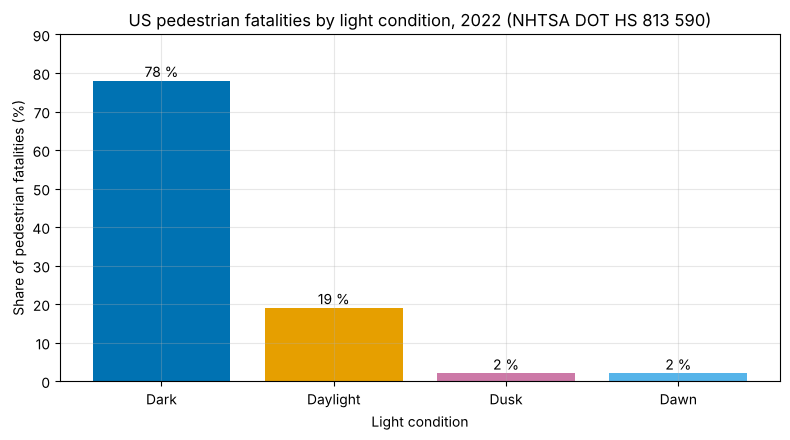

--- Light condition (text summary) ---
  Dark: 78 %
  Daylight: 19 %
  Dusk: 2 %
  Dawn: 2 %
  ~78 % of US pedestrian fatalities in 2022 occurred in the dark (percentages are rounded and sum to 101).
  Caveat: this is crash data for human-driven traffic; it shows where the risk is, not how a detector performs.


In [4]:
# NHTSA Traffic Safety Facts 2022 (DOT HS 813 590): US pedestrian fatalities by light condition
light = pd.DataFrame({'Condition': ['Dark', 'Daylight', 'Dusk', 'Dawn'], 'Percentage': [78, 19, 2, 2]})
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(light['Condition'], light['Percentage'], color=[OKABE_ITO[4], OKABE_ITO[0], OKABE_ITO[6], OKABE_ITO[1]])
for i, p in enumerate(light['Percentage']):
    ax.text(i, p + 1, f"{p} %", ha='center')
ax.set_ylabel('Share of pedestrian fatalities (%)'); ax.set_xlabel('Light condition')
ax.set_title('US pedestrian fatalities by light condition, 2022 (NHTSA DOT HS 813 590)')
ax.set_ylim(0, 90); plt.tight_layout(); plt.show()

dark = int(light.loc[light.Condition == 'Dark', 'Percentage'].iloc[0])
print("--- Light condition (text summary) ---")
for _, r in light.iterrows():
    print(f"  {r['Condition']}: {r['Percentage']} %")
print(f"  ~{dark} % of US pedestrian fatalities in 2022 occurred in the dark (percentages are rounded and sum to {light.Percentage.sum()}).")
print("  Caveat: this is crash data for human-driven traffic; it shows where the risk is, not how a detector performs.")

VRUs are not one homogeneous class. Sub-groups that detectors often find harder include children (small, partly hidden by parked cars), wheelchair users and people pushing objects (unusual silhouettes), and people in dark clothing at night. Keep the chart above in mind: about four in five US pedestrian fatalities happen in the dark, and **KITTI contains no night images at all** — every number measured below is a daytime number.

---
## 2. Choosing frames that contain VRUs

A random sample of KITTI frames contains few distant or occluded VRUs. We therefore select frames **from the label table**: each frame's pedestrians and cyclists are counted per distance band (0–10, 10–20, 20–30, 30–45, 45–80 m), and 40 frames are picked greedily so that each class × band cell reaches up to 14 objects. Frames used in notebook 04 are excluded, so the two notebooks use independent frames.

In [5]:
labels_all = D.kitti_object_labels_all()
FRAMES_04 = [95, 193, 564, 804, 1234, 1355, 1460, 2007, 2439, 2666, 2715, 2727, 2739, 3254, 3287, 3343, 3390, 3398,
             3480, 3570, 3686, 4364, 4447, 4515, 4613, 4737, 4753, 4790, 5495, 5878, 6010, 6176, 6204, 6277, 6690, 7404]
BANDS = [0, 10, 20, 30, 45, 80]

vru_lab = labels_all[labels_all['type'].isin(['Pedestrian', 'Cyclist'])].copy()
vru_lab['band'] = pd.cut(vru_lab['distance_m'], BANDS, labels=False)
M = vru_lab.pivot_table(index='frame', columns=['type', 'band'], aggfunc='size', fill_value=0)
M = M[~M.index.astype(int).isin(FRAMES_04)]
need, chosen, A_ = np.full(M.shape[1], 14.0), [], M.to_numpy(float)
for _ in range(40):                                   # greedy cover of class x distance cells
    gain = np.minimum(A_, need).sum(1) + 0.01 * A_.sum(1)
    gain[[M.index.get_loc(c) for c in chosen]] = -1
    k = int(np.argmax(gain)); chosen.append(M.index[k]); need = np.maximum(need - A_[k], 0)
VRU_FRAMES = [134, 317, 362, 366, 736, 874, 928, 966, 1366, 1404, 2149, 2171, 2362, 2379, 2487, 2707, 2742, 2920,
              3050, 3114, 3454, 3464, 3502, 4065, 4139, 4338, 4567, 4665, 4747, 5226, 5511, 5663, 5965, 5988,
              6121, 6139, 6422, 6583, 6682, 6980]
assert sorted(int(c) for c in chosen) == VRU_FRAMES, "frame selection changed"

sel = labels_all[labels_all['frame'].astype(int).isin(VRU_FRAMES) & labels_all['type'].isin(['Pedestrian', 'Person_sitting', 'Cyclist'])]
print(f"{len(VRU_FRAMES)} frames with {len(sel)} labelled VRUs "
      f"({(sel['type'] == 'Pedestrian').sum()} pedestrians, {(sel['type'] == 'Cyclist').sum()} cyclists, "
      f"{(sel['type'] == 'Person_sitting').sum()} seated persons)")
display(pd.crosstab(sel['type'], pd.cut(sel['distance_m'], BANDS)))

40 frames with 457 labelled VRUs (377 pedestrians, 78 cyclists, 2 seated persons)


distance_m,"(0, 10]","(10, 20]","(20, 30]","(30, 45]","(45, 80]"
type,,,,,
Cyclist,14,19,16,15,14
Pedestrian,97,143,83,40,14
Person_sitting,1,1,0,0,0


In [6]:
MODEL_NAME = 'fasterrcnn_mobilenet_v3_large_fpn'
COCO_NAMES = {1: 'person', 2: 'bicycle', 3: 'car', 4: 'motorcycle', 6: 'bus', 8: 'truck'}
DET_DIR = D.cache_dir() / 'detections' / f"{MODEL_NAME}_tv{torchvision.__version__.split('+')[0]}"
_model = None

def get_model():
    global _model
    if _model is None:
        _model = fasterrcnn_mobilenet_v3_large_fpn(weights='DEFAULT').eval()   # COCO weights, ~75 MB once
    return _model

def detect(index, image=None):
    # Raw COCO detections (score >= 0.05) for KITTI training frame `index`, cached on disk after the first run.
    path = DET_DIR / f'{index:06d}.npz'
    if path.exists():
        with np.load(path) as z:
            return {k: z[k] for k in z.files}
    if image is None:
        image = D.kitti_object(index, parts=('image',)).image
    x = torch.from_numpy(image.copy()).permute(2, 0, 1).float() / 255
    t0 = time.perf_counter()
    with torch.no_grad():
        out = get_model()([x])[0]
    res = {'boxes': out['boxes'].numpy(), 'labels': out['labels'].numpy(), 'scores': out['scores'].numpy(),
           'latency_ms': np.array(1000 * (time.perf_counter() - t0))}
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.stem + f'.{os.getpid()}.tmp.npz')
    np.savez(tmp, **res); os.replace(tmp, path)
    return res

def to_kitti(raw):
    # Map COCO detections of one frame to KITTI classes (see the table above).
    names = [COCO_NAMES.get(int(c)) for c in raw['labels']]
    boxes, scores = raw['boxes'], raw['scores']
    persons = [i for i, n in enumerate(names) if n == 'person']
    bikes = sorted((i for i, n in enumerate(names) if n == 'bicycle'), key=lambda i: -scores[i])
    used, out = set(), []
    for b in bikes:                                   # rider = person overlapping the bicycle horizontally, above it
        bx, best = boxes[b], None
        for p in persons:
            px = boxes[p]
            overlap_x = max(0.0, min(px[2], bx[2]) - max(px[0], bx[0])) / max(px[2] - px[0], 1e-6)
            if p not in used and overlap_x >= 0.5 and px[1] < bx[1] < px[3] and (best is None or scores[p] > scores[best]):
                best = p
        if best is not None:
            used.add(best); px = boxes[best]
            out.append({'cls': 'Cyclist', 'score': float(np.sqrt(scores[b] * scores[best])), 'coco': 'person+bicycle',
                        'box': np.array([min(px[0], bx[0]), min(px[1], bx[1]), max(px[2], bx[2]), max(px[3], bx[3])])})
    for i, n in enumerate(names):
        if n == 'car':
            out.append({'cls': 'Car', 'score': float(scores[i]), 'box': boxes[i], 'coco': n})
        elif n == 'person' and i not in used:
            out.append({'cls': 'Pedestrian', 'score': float(scores[i]), 'box': boxes[i], 'coco': n})
    return out

frames, raw_dets, t_start = {}, {}, time.perf_counter()
for idx in VRU_FRAMES:
    try:
        frames[idx] = D.kitti_object(idx, parts=('image', 'labels'))
    except D.DataUnavailable as exc:
        raise SystemExit(f"KITTI not reachable ({exc}). This notebook needs network access once; then it runs from cache.")
    for l in frames[idx].labels:
        l['difficulty'] = D.kitti_difficulty(l)
    raw_dets[idx] = detect(idx, frames[idx].image)
dets = {idx: to_kitti(r) for idx, r in raw_dets.items()}
n_raw = sum(len(r['scores']) for r in raw_dets.values())
print(f"Detector: {MODEL_NAME} (COCO weights); {len(VRU_FRAMES)} frames processed in {time.perf_counter() - t_start:.0f} s "
      f"(including any downloads; cached afterwards)")
print(f"{n_raw} raw detections with score >= 0.05 -> {sum(map(len, dets.values()))} after mapping to KITTI classes")

Detector: fasterrcnn_mobilenet_v3_large_fpn (COCO weights); 40 frames processed in 1 s (including any downloads; cached afterwards)
3305 raw detections with score >= 0.05 -> 1845 after mapping to KITTI classes


---
## 3. VRU recall measured on real frames

For automatic emergency braking the first question is *"is there a vulnerable road user in my path?"*, not *"pedestrian or cyclist?"*. We therefore measure **class-agnostic VRU recall**: a labelled pedestrian, seated person or cyclist counts as detected if a mapped Pedestrian or Cyclist detection with score ≥ 0.5 overlaps it with IoU ≥ 0.5 (one-to-one, greedy by score). All labelled VRUs are included, also those KITTI itself would ignore (too small, occluded, truncated), because a real pedestrian does not become harmless by being hard to see. Intervals are 95 % Clopper–Pearson intervals.

In [7]:
OP_THR, IOU_MIN = 0.5, 0.5
VRU_TYPES = ('Pedestrian', 'Person_sitting', 'Cyclist')

def iou_matrix(A, B):
    A, B = np.asarray(A, float).reshape(-1, 4), np.asarray(B, float).reshape(-1, 4)
    ix1 = np.maximum(A[:, None, 0], B[None, :, 0]); iy1 = np.maximum(A[:, None, 1], B[None, :, 1])
    ix2 = np.minimum(A[:, None, 2], B[None, :, 2]); iy2 = np.minimum(A[:, None, 3], B[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    area = lambda X: (X[:, 2] - X[:, 0]) * (X[:, 3] - X[:, 1])
    return np.where(inter > 0, inter / np.maximum(area(A)[:, None] + area(B)[None, :] - inter, 1e-12), 0.0)

def clopper_pearson(k, n, conf=0.95):
    a = (1 - conf) / 2
    return (beta.ppf(a, k, n - k + 1) if k > 0 else 0.0, beta.ppf(1 - a, k + 1, n - k) if k < n else 1.0)

rows = []
for idx in VRU_FRAMES:
    gts = [l for l in frames[idx].labels if l['type'] in VRU_TYPES]
    cand = sorted((d for d in dets[idx] if d['cls'] in ('Pedestrian', 'Cyclist')), key=lambda d: -d['score'])
    gb = np.array([[l['x1'], l['y1'], l['x2'], l['y2']] for l in gts]).reshape(-1, 4)
    ov = iou_matrix([d['box'] for d in cand], gb)
    best_score = np.full(len(gts), np.nan); taken = np.zeros(len(gts), bool)
    for k, d in enumerate(cand):                       # greedy one-to-one matching
        js = np.where(~taken & (ov[k] >= IOU_MIN))[0]
        if len(js):
            j = js[np.argmax(ov[k][js])]; taken[j] = True; best_score[j] = d['score']
    others = iou_matrix(gb, gb) - np.eye(len(gts))
    for j, l in enumerate(gts):
        rows.append({'frame': idx, 'type': l['type'], 'distance_m': np.hypot(l['x'], l['z']),
                     'height_px': l['y2'] - l['y1'], 'occluded': l['occluded'], 'truncated': l['truncated'],
                     'difficulty': l['difficulty'], 'crowded': bool(len(gts) > 1 and others[j].max() > 0.3),
                     'score': best_score[j], 'box': [l['x1'], l['y1'], l['x2'], l['y2']]})
vru = pd.DataFrame(rows)
vru['found'] = vru['score'] >= OP_THR
k, n = int(vru['found'].sum()), len(vru)
lo, hi = clopper_pearson(k, n)
print(f"Overall VRU recall at score >= {OP_THR}: {k}/{n} = {k / n:.2f} (95 % CI {lo:.2f}-{hi:.2f})")
for t, g in vru.groupby('type'):
    print(f"  {t:15s}: {g['found'].mean():.2f} of {len(g)}")
for L in ['Easy', 'Moderate', 'Hard', 'Ignored']:
    g = vru[vru['difficulty'] == L]
    print(f"  KITTI difficulty {L:8s}: recall {g['found'].mean():.2f} (n = {len(g)})")

Overall VRU recall at score >= 0.5: 185/457 = 0.40 (95 % CI 0.36-0.45)
  Cyclist        : 0.35 of 78
  Pedestrian     : 0.42 of 377
  Person_sitting : 0.00 of 2
  KITTI difficulty Easy    : recall 0.71 (n = 170)
  KITTI difficulty Moderate: recall 0.25 (n = 195)
  KITTI difficulty Hard    : recall 0.02 (n = 63)
  KITTI difficulty Ignored : recall 0.52 (n = 29)


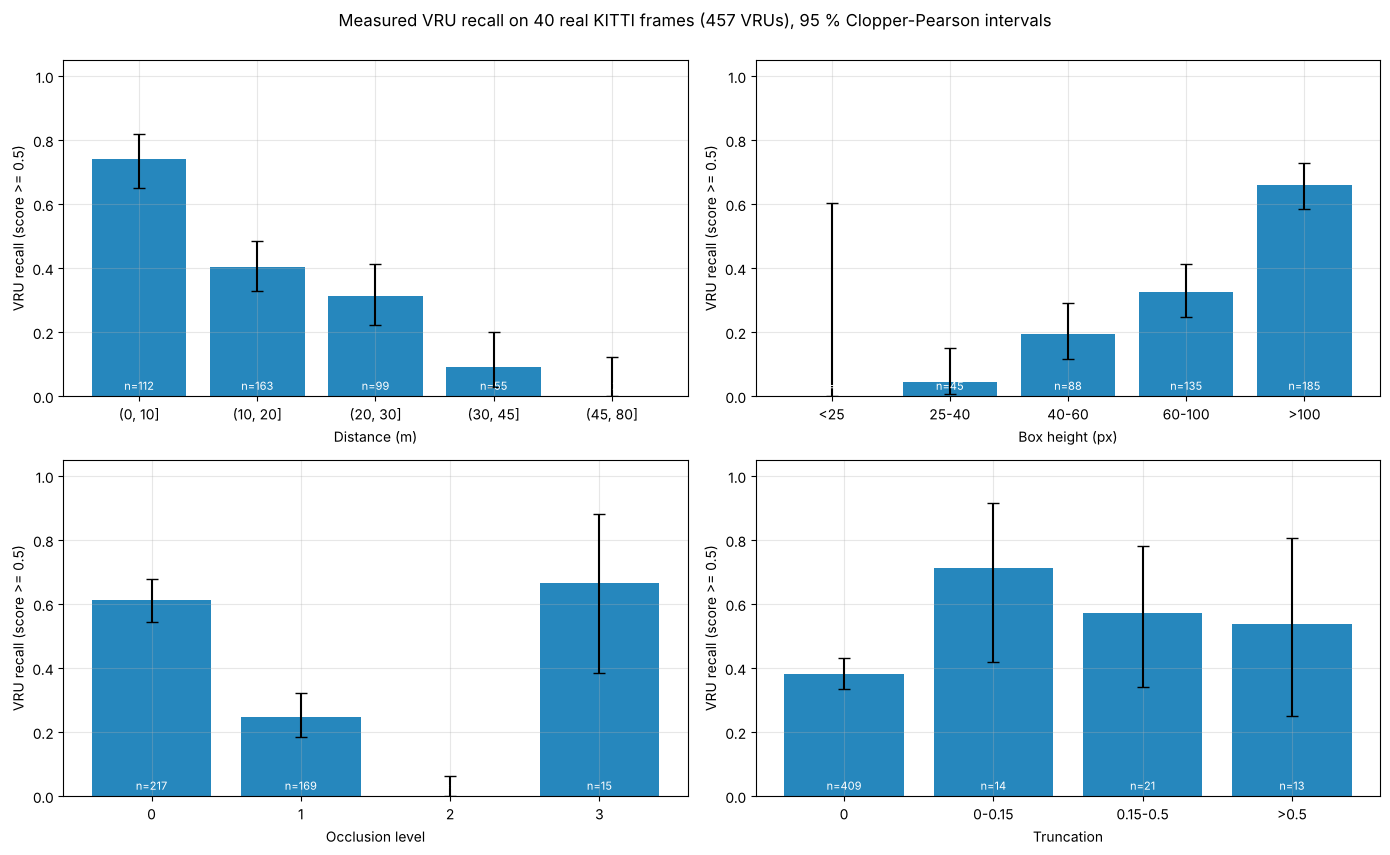

Distance (m): (0, 10] 0.74 (n=112); (10, 20] 0.40 (n=163); (20, 30] 0.31 (n=99); (30, 45] 0.09 (n=55); (45, 80] 0.00 (n=28)
Box height (px): <25 0.00 (n=4); 25-40 0.04 (n=45); 40-60 0.19 (n=88); 60-100 0.33 (n=135); >100 0.66 (n=185)
Occlusion level: 0 0.61 (n=217); 1 0.25 (n=169); 2 0.00 (n=56); 3 0.67 (n=15)
Truncation: 0 0.38 (n=409); 0-0.15 0.71 (n=14); 0.15-0.5 0.57 (n=21); >0.5 0.54 (n=13)


In [8]:
def recall_table(col, bins=None, labels=None):
    key = pd.cut(vru[col], bins, labels=labels) if bins is not None else vru[col]
    out = []
    for b, g in vru.groupby(key, observed=True):
        k, n = int(g['found'].sum()), len(g); lo, hi = clopper_pearson(k, n)
        out.append({'bin': str(b), 'n': n, 'recall': k / n, 'lo': lo, 'hi': hi})
    return pd.DataFrame(out)

tabs = {
    'Distance (m)': recall_table('distance_m', BANDS),
    'Box height (px)': recall_table('height_px', [0, 25, 40, 60, 100, 400], ['<25', '25-40', '40-60', '60-100', '>100']),
    'Occlusion level': recall_table('occluded'),
    'Truncation': recall_table('truncated', [-0.01, 0.0, 0.15, 0.5, 1.0], ['0', '0-0.15', '0.15-0.5', '>0.5']),
}
fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))
for ax, (name, t) in zip(axes.ravel(), tabs.items()):
    x = np.arange(len(t))
    ax.bar(x, t['recall'], color=OKABE_ITO[4], alpha=0.85)
    ax.errorbar(x, t['recall'], yerr=[t['recall'] - t['lo'], t['hi'] - t['recall']], fmt='none', ecolor='black', capsize=4)
    for xi, (r, nn) in enumerate(zip(t['recall'], t['n'])):
        ax.text(xi, 0.02, f"n={nn}", ha='center', color='white', fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(t['bin'], rotation=0); ax.set_ylim(0, 1.05)
    ax.set_xlabel(name); ax.set_ylabel(f'VRU recall (score >= {OP_THR})')
fig.suptitle(f'Measured VRU recall on {len(VRU_FRAMES)} real KITTI frames ({n} VRUs), 95 % Clopper-Pearson intervals', y=1.0)
plt.tight_layout(); plt.show()
for name, t in tabs.items():
    print(f"{name}: " + "; ".join(f"{b} {r:.2f} (n={nn})" for b, r, nn in zip(t['bin'], t['recall'], t['n'])))

### Real hits and misses

Crops of VRUs at increasing distance: top row detected (with score), bottom row missed. The occlusion level and box height come from the KITTI label.

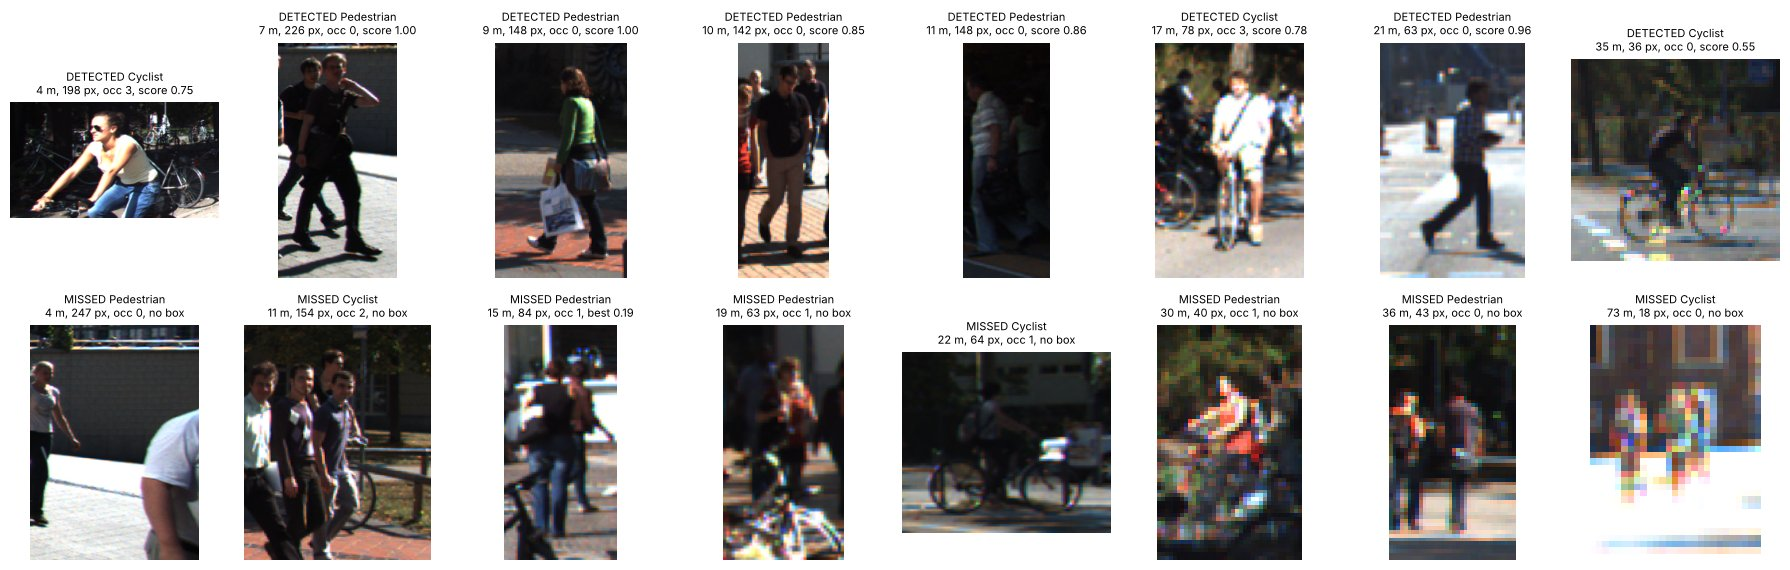

272 missed VRUs. Share of misses with each property (they overlap):
  box height < 40 px                      17.3 %
  partly/largely occluded (occ 1-2)       67.3 %
  occlusion unknown (occ 3)                1.8 %
  truncated > 15 %                         5.5 %
  crowded (IoU > 0.3 with another VRU)    29.4 %
  none of these (visible, large, isolated)   12.5 %  <- the model's own blind spots
  70 misses had a matching box below 0.5 (threshold), 202 had none (model).


In [9]:
def crop(idx, box, pad=10):
    im = frames[idx].image; h, w = im.shape[:2]
    x1, y1, x2, y2 = [int(round(v)) for v in box]
    return im[max(0, y1 - pad):min(h, y2 + pad), max(0, x1 - pad):min(w, x2 + pad)]

n_show = 8
fig, axes = plt.subplots(2, n_show, figsize=(18, 5.8))
for row, (flag, title) in enumerate([(True, 'DETECTED'), (False, 'MISSED')]):
    g = vru[vru['found'] == flag].sort_values('distance_m')
    pick = g.iloc[np.linspace(0, len(g) - 1, min(n_show, len(g))).astype(int)] if len(g) else g
    for ax in axes[row]:
        ax.axis('off')
    for ax, r in zip(axes[row], pick.to_dict('records')):
        ax.imshow(crop(r['frame'], r['box']))
        s = f", score {r['score']:.2f}" if flag else (f", best {r['score']:.2f}" if r['score'] == r['score'] else ', no box')
        ax.set_title(f"{title} {r['type'][:10]}\n{r['distance_m']:.0f} m, {r['height_px']:.0f} px, occ {r['occluded']}{s}", fontsize=8)
plt.tight_layout(); plt.show()

miss = vru[~vru['found']]
reasons = pd.Series({
    'box height < 40 px': (miss['height_px'] < 40).mean(),
    'partly/largely occluded (occ 1-2)': miss['occluded'].isin([1, 2]).mean(),
    'occlusion unknown (occ 3)': (miss['occluded'] == 3).mean(),
    'truncated > 15 %': (miss['truncated'] > 0.15).mean(),
    'crowded (IoU > 0.3 with another VRU)': miss['crowded'].mean(),
})
none = ~((miss['height_px'] < 40) | (miss['occluded'] >= 1) | (miss['truncated'] > 0.15) | miss['crowded'])
print(f"{len(miss)} missed VRUs. Share of misses with each property (they overlap):")
for k_, v_ in reasons.items():
    print(f"  {k_:38s} {100 * v_:5.1f} %")
print(f"  none of these (visible, large, isolated)  {100 * none.mean():5.1f} %  <- the model's own blind spots")
print(f"  {int(miss['score'].notna().sum())} misses had a matching box below {OP_THR} (threshold), "
      f"{int(miss['score'].isna().sum())} had none (model).")

**Observation.** The failure modes are not hypothetical: on these real frames, misses concentrate on small (distant) VRUs, occluded VRUs and VRUs in groups — the triggering conditions listed in every SOTIF analysis of pedestrian AEB. The few misses of large, visible, isolated VRUs are the model's own insufficiencies and deserve individual review (pose, clothing, unusual appearance, label error).

---
## 4. Choosing the operating threshold from a measured PR curve

The threshold is chosen against a **recall target**, not at the maximum F1 score. Here we use the KITTI-evaluable VRUs (difficulty Easy–Hard). Detections that match a VRU outside this set, lie in a `DontCare` region or are lower than 25 px are ignored, as in notebook 04.

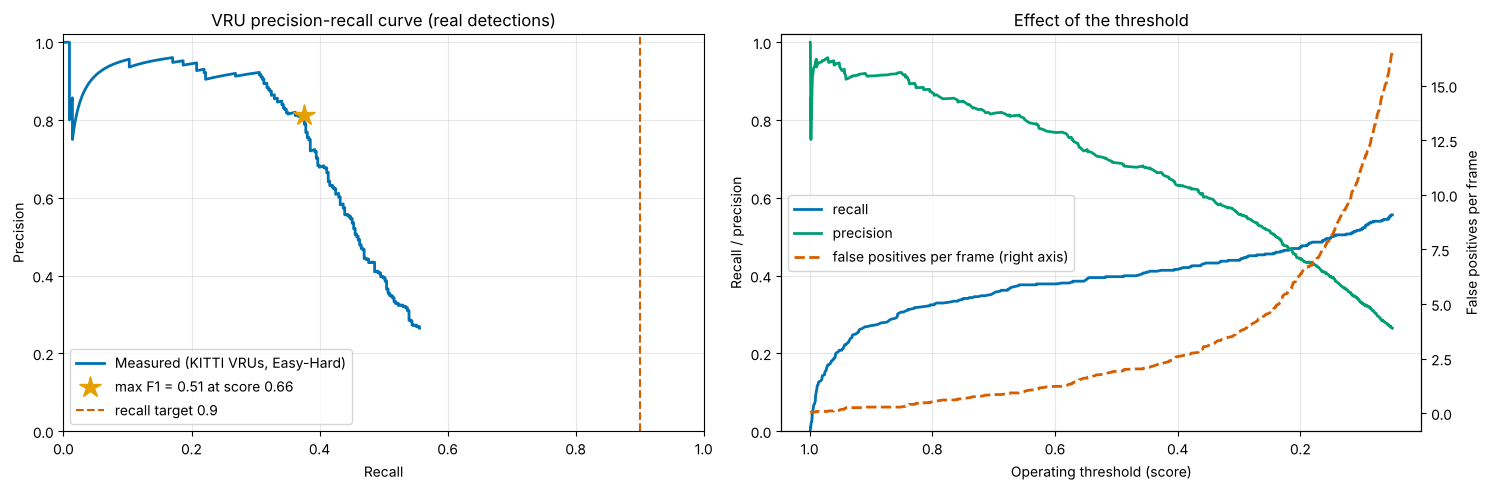

428 evaluable VRUs. Maximum recall at any threshold: 0.556.
Max-F1 threshold 0.66: recall 0.38, precision 0.81, 0.93 FP per frame.
Recall target 0.9 is NOT reachable at any threshold: the model, not the threshold, must change.


In [10]:
def vru_pr():
    scores, tp, n_gt = [], [], 0
    for idx in VRU_FRAMES:
        labs = frames[idx].labels
        gts = [l for l in labs if l['type'] in VRU_TYPES]
        valid = np.array([l['difficulty'] != 'Ignored' for l in gts], bool); n_gt += int(valid.sum())
        gb = np.array([[l['x1'], l['y1'], l['x2'], l['y2']] for l in gts]).reshape(-1, 4)
        dc = np.array([[l['x1'], l['y1'], l['x2'], l['y2']] for l in labs if l['type'] == 'DontCare']).reshape(-1, 4)
        cand = sorted((d for d in dets[idx] if d['cls'] in ('Pedestrian', 'Cyclist')), key=lambda d: -d['score'])
        ov = iou_matrix([d['box'] for d in cand], gb); taken = np.zeros(len(gts), bool)
        for k, d in enumerate(cand):
            js = np.where(~taken & (ov[k] >= IOU_MIN))[0]
            if len(js):
                j = js[np.argmax(ov[k][js])]; taken[j] = True
                if valid[j]:
                    scores.append(d['score']); tp.append(True)
                continue
            b = d['box']
            in_dc = len(dc) and ((np.clip(np.minimum(b[2], dc[:, 2]) - np.maximum(b[0], dc[:, 0]), 0, None) *
                                  np.clip(np.minimum(b[3], dc[:, 3]) - np.maximum(b[1], dc[:, 1]), 0, None)) /
                                 max((b[2] - b[0]) * (b[3] - b[1]), 1e-6)).max() >= 0.5
            if not in_dc and b[3] - b[1] >= 25:
                scores.append(d['score']); tp.append(False)
    o = np.argsort(-np.array(scores), kind='stable')
    s, t = np.array(scores)[o], np.array(tp)[o]
    ctp, cfp = np.cumsum(t), np.cumsum(~t)
    return s, ctp / n_gt, ctp / np.maximum(ctp + cfp, 1), cfp, n_gt

s, rec, prec, cfp, n_gt = vru_pr()
f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12); i_f1 = int(np.argmax(f1))
TARGET = 0.90
ok = np.where(rec >= TARGET)[0]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(rec, prec, color=OKABE_ITO[4], lw=2, label='Measured (KITTI VRUs, Easy-Hard)')
axes[0].plot(rec[i_f1], prec[i_f1], '*', ms=16, color=OKABE_ITO[0], label=f'max F1 = {f1[i_f1]:.2f} at score {s[i_f1]:.2f}')
axes[0].axvline(TARGET, color=OKABE_ITO[5], ls='--', label=f'recall target {TARGET}')
axes[0].set_xlabel('Recall'); axes[0].set_ylabel('Precision'); axes[0].set_xlim(0, 1); axes[0].set_ylim(0, 1.02)
axes[0].legend(loc='lower left'); axes[0].set_title('VRU precision-recall curve (real detections)')
axes[1].plot(s, rec, color=OKABE_ITO[4], lw=2, label='recall')
axes[1].plot(s, prec, color=OKABE_ITO[2], lw=2, label='precision')
axes[1].set_ylabel('Recall / precision'); axes[1].set_ylim(0, 1.02)
ax2 = axes[1].twinx(); ax2.grid(False)
ax2.plot(s, cfp / len(VRU_FRAMES), color=OKABE_ITO[5], lw=2, ls='--', label='false positives per frame (right axis)')
ax2.set_ylabel('False positives per frame')
axes[1].set_xlabel('Operating threshold (score)'); axes[1].invert_xaxis()
h1, l1 = axes[1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
axes[1].legend(h1 + h2, l1 + l2, loc='center left')
axes[1].set_title('Effect of the threshold')
plt.tight_layout(); plt.show()
print(f"{n_gt} evaluable VRUs. Maximum recall at any threshold: {rec.max():.3f}.")
print(f"Max-F1 threshold {s[i_f1]:.2f}: recall {rec[i_f1]:.2f}, precision {prec[i_f1]:.2f}, "
      f"{cfp[i_f1] / len(VRU_FRAMES):.2f} FP per frame.")
if len(ok):
    i = ok[0]
    print(f"Recall target {TARGET}: threshold {s[i]:.2f}, precision {prec[i]:.2f}, {cfp[i] / len(VRU_FRAMES):.2f} FP per frame "
          f"({cfp[i] / len(VRU_FRAMES) * 10 * 3600:,.0f} per hour at 10 Hz before tracking).")
else:
    print(f"Recall target {TARGET} is NOT reachable at any threshold: the model, not the threshold, must change.")

A recall target forces the threshold down and the false-positive rate up. Every false VRU that reaches the AEB decision logic is a candidate for unintended braking — the hazard behind **SG-01 (ASIL D)** in this course's HARA. That is why VRU detections are confirmed over several frames (tracking) and by a second sensor before they trigger braking.

---
## 5. What this means for AEB: required versus measured detection range

To avoid a collision with a pedestrian standing in the lane, the system must detect and confirm the pedestrian at least at the **stopping distance**

$$ d_{stop} = v\,t_r + \frac{v^2}{2a}, $$

with $t_r$ = 0.5 s for confirmation and brake build-up and $a$ = 8.0 m/s² (dry) or 5.5 m/s² (wet), the same assumptions as in [04_SOTIF_ISO21448/02](../04_SOTIF_ISO21448/02_triggering_conditions_and_scenarios.ipynb). The formula is `avsafety.sotif.stopping_distance`.

> **Illustrative data:** $t_r$ and $a$ are assumptions for teaching; a real AEB specification derives them from the brake system and the confirmation logic.

We fit a logistic curve of recall against distance to the **fully visible, untruncated** VRUs (the best case) and read off the distance up to which recall stays at or above 0.9.

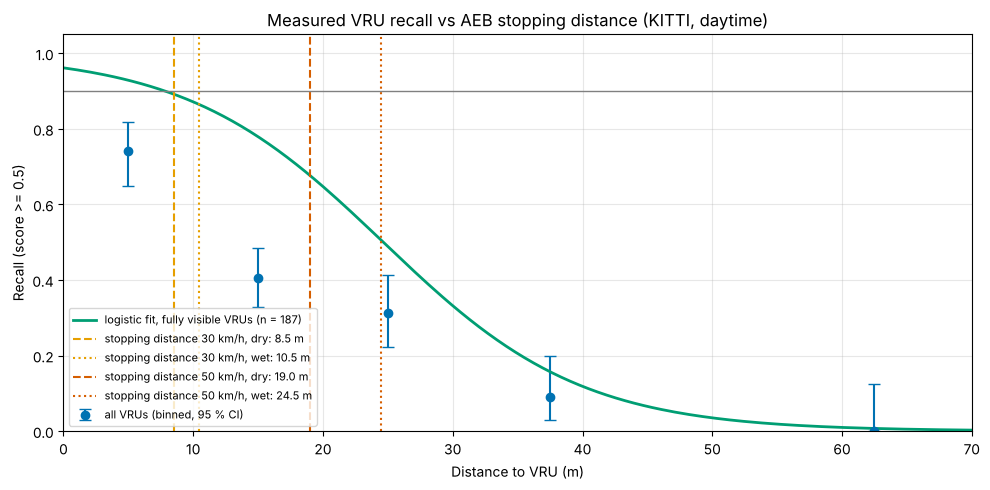

  30 km/h, dry: stopping distance   8.5 m -> a 1.75 m pedestrian is  145 px high; fitted recall there 0.89 (fully visible)
  30 km/h, wet: stopping distance  10.5 m -> a 1.75 m pedestrian is  118 px high; fitted recall there 0.86 (fully visible)
  50 km/h, dry: stopping distance  19.0 m -> a 1.75 m pedestrian is   65 px high; fitted recall there 0.68 (fully visible)
  50 km/h, wet: stopping distance  24.5 m -> a 1.75 m pedestrian is   51 px high; fitted recall there 0.51 (fully visible)
Camera focal length f = 707.0 px.
Fitted distance up to which recall >= 0.9 for fully visible VRUs: 8 m.
Track view: if misses were independent, at least one detection in 3 frames at the 50 km/h wet distance would have probability 1 - (1 - 0.51)^3 = 0.88; correlated misses (occlusion, crowds) make it lower.
All VRUs beyond the 50 km/h wet stopping distance: recall 0.11 (n = 112); occluded ones (occ >= 1) among all: recall 0.22.


In [11]:
T_R, DECEL = 0.5, {'dry': 8.0, 'wet': 5.5}
req = {(v, s_): stopping_distance(v / 3.6, T_R, a) for v in (30, 50) for s_, a in DECEL.items()}

clean = vru[(vru['occluded'] == 0) & (vru['truncated'] <= 0.0)]
d, y = clean['distance_m'].to_numpy(), clean['found'].to_numpy(float)
def nll(p):
    z = p[0] + p[1] * d
    return np.sum(np.logaddexp(0, z) - y * z)
fit = minimize(nll, x0=[2.0, -0.05], method='Nelder-Mead')
b0, b1 = fit.x
p_hat = lambda x: 1 / (1 + np.exp(-(b0 + b1 * x)))
d90 = (np.log(0.9 / 0.1) - b0) / b1 if b1 < 0 else np.inf

fig, ax = plt.subplots(figsize=(10, 5))
t = recall_table('distance_m', BANDS)
mids = [(a + b) / 2 for a, b in zip(BANDS[:-1], BANDS[1:])][:len(t)]
ax.errorbar(mids, t['recall'], yerr=[t['recall'] - t['lo'], t['hi'] - t['recall']], fmt='o', color=OKABE_ITO[4],
            capsize=4, label='all VRUs (binned, 95 % CI)')
xx = np.linspace(0, 70, 200)
ax.plot(xx, p_hat(xx), color=OKABE_ITO[2], lw=2, label=f'logistic fit, fully visible VRUs (n = {len(clean)})')
for (v, s_), dist in req.items():
    ax.axvline(dist, color=OKABE_ITO[5] if v == 50 else OKABE_ITO[0], ls='--' if s_ == 'dry' else ':',
               label=f'stopping distance {v} km/h, {s_}: {dist:.1f} m')
ax.axhline(0.9, color='grey', lw=1)
ax.set_xlabel('Distance to VRU (m)'); ax.set_ylabel(f'Recall (score >= {OP_THR})'); ax.set_ylim(0, 1.05); ax.set_xlim(0, 70)
ax.legend(fontsize=8, loc='lower left'); ax.set_title('Measured VRU recall vs AEB stopping distance (KITTI, daytime)')
plt.tight_layout(); plt.show()

f_px = float(D.kitti_object(VRU_FRAMES[0], parts=('calib',)).calib['P2'][0, 0])   # focal length (px) from the KITTI calibration
for (v, s_), dist in req.items():
    print(f"  {v} km/h, {s_:3s}: stopping distance {dist:5.1f} m -> a 1.75 m pedestrian is {f_px * 1.75 / dist:4.0f} px high; "
          f"fitted recall there {p_hat(dist):.2f} (fully visible)")
print(f"Camera focal length f = {f_px:.1f} px.")
print(f"Fitted distance up to which recall >= 0.9 for fully visible VRUs: {d90:.0f} m.")
p50 = p_hat(req[(50, 'wet')])
print(f"Track view: if misses were independent, at least one detection in 3 frames at the 50 km/h wet distance would have "
      f"probability 1 - (1 - {p50:.2f})^3 = {1 - (1 - p50) ** 3:.2f}; correlated misses (occlusion, crowds) make it lower.")
far = vru[vru['distance_m'] > req[(50, 'wet')]]
print(f"All VRUs beyond the 50 km/h wet stopping distance: recall {far['found'].mean():.2f} (n = {len(far)}); "
      f"occluded ones (occ >= 1) among all: recall {vru[vru['occluded'] >= 1]['found'].mean():.2f}.")

**Interpretation** (compare with the printed numbers).

- The required range is short at 30 km/h (about 9–11 m) and grows to about 19–25 m at 50 km/h. For the off-the-shelf COCO model, even *fully visible* VRUs are detected per frame with clearly less than 0.9 probability at the 50 km/h distances, and occluded or grouped VRUs much less often. This detector, used alone, would not support a pedestrian AEB at 50 km/h. Production systems use detectors trained on driving data, cameras with more pixels on distant objects, tracking, and fusion with radar or LiDAR — and must then *show* the improvement with the same kind of measurement.
- Tracking helps only as far as misses are independent: a pedestrian behind a parked car is missed in every frame, and a person inside a group is often missed repeatedly (Section 3).
- A pedestrian who **steps out from behind a parked car** is visible only for the last few metres; no detector can see through the car. Such cases are handled by speed reduction, by the AEB's scenario limits, or by other sensors — they are SOTIF triggering conditions, not detector bugs.
- KITTI has **no night or rain frames**. The 78 % of pedestrian fatalities that occur in the dark are outside everything measured here. A claim about AEB at night needs night data (see [08 Driving datasets](08_driving_datasets.ipynb)).
- The pedestrian-relevant scope of the course's AEB item is **urban driving ≤ 60 km/h**; the required range grows with $v^2$, so the upper end of that scope is where detection performance must be demonstrated.

---
## 6. Exercise: from recall to risk

**Scenario:** after testing on 1 million frames the pedestrian detector produced, over 50,000 pedestrian *instances* (a pedestrian visible in a frame): 49,500 TP, 1,000 FP and 500 FN.

1. Compute precision and recall.
2. Does it meet an (illustrative) target of recall ≥ 99.9 %?
3. What does a miss mean physically?
4. What would you improve?

In [12]:
tp_, fp_, fn_ = 49_500, 1_000, 500
n_instances = tp_ + fn_
precision_ = tp_ / (tp_ + fp_); recall_ = tp_ / (tp_ + fn_); f1_ = 2 * precision_ * recall_ / (precision_ + recall_)
print(f"Precision {precision_:.4f}, recall {recall_:.4f}, F1 {f1_:.4f}, miss rate {fn_/n_instances:.4f}")
target = 0.999
print(f"Recall target {target}: {'met' if recall_ >= target else 'NOT met'} "
      f"({fn_} missed pedestrian instances (frame-level) per {n_instances:,}; target allows {int(n_instances*(1-target))})")

fps, v = 30, 50 / 3.6
print(f"\nDistance travelled while a pedestrian goes unseen at 50 km/h ({fps} fps camera):")
for k in (1, 3, 10, 30):
    print(f"  {k:2d} consecutive missed frame(s) = {k * v / fps:5.2f} m")
print(f"Expected missed pedestrian-frames per second at {fps} fps if one pedestrian is always visible: {fps * fn_ / n_instances:.2f}")

Precision 0.9802, recall 0.9900, F1 0.9851, miss rate 0.0100
Recall target 0.999: NOT met (500 missed pedestrian instances (frame-level) per 50,000; target allows 50)

Distance travelled while a pedestrian goes unseen at 50 km/h (30 fps camera):
   1 consecutive missed frame(s) =  0.46 m
   3 consecutive missed frame(s) =  1.39 m
  10 consecutive missed frame(s) =  4.63 m
  30 consecutive missed frame(s) = 13.89 m
Expected missed pedestrian-frames per second at 30 fps if one pedestrian is always visible: 0.30


### Frame-level vs track-level recall

Whether 1 % of missed frames matters depends on **how misses are distributed in time**. If misses are independent, a tracker that needs, say, 3 hits out of 5 frames almost never loses a pedestrian; if misses come in long bursts (a pedestrian behind a parked van, or in glare), the track is lost for exactly as long as the burst lasts. Tracking is the subject of [07 Multi-object tracking](07_multi_object_tracking.ipynb).

> **Illustrative data:** simulated miss sequences, chosen for teaching.

In [13]:
def simulate_misses(n_frames, p_miss, burst_len, rng):
    """Binary miss sequence with average miss rate p_miss; misses come in bursts of mean length burst_len."""
    if burst_len <= 1:
        return rng.random(n_frames) < p_miss
    p_exit = 1 / burst_len                          # two-state Markov chain (seen <-> missed)
    p_enter = p_miss * p_exit / (1 - p_miss)
    m = np.zeros(n_frames, bool); state = False
    for i in range(n_frames):
        state = (rng.random() >= p_exit) if state else (rng.random() < p_enter)
        m[i] = state
    return m

def longest_run(m):
    best = cur = 0
    for x in m:
        cur = cur + 1 if x else 0; best = max(best, cur)
    return best

n_frames, p = 30 * 60 * 60, 0.01             # 1 hour at 30 fps, 1 % frame misses
rows = []
for burst in [1, 5, 15, 45]:
    m = simulate_misses(n_frames, p, burst, np.random.default_rng(burst))
    lr = longest_run(m)
    rows.append({'mean burst length (frames)': burst, 'observed miss rate': round(m.mean(), 4),
                 'longest blind run (frames)': lr, 'longest blind distance at 50 km/h (m)': round(lr * v / fps, 1)})
burst_df = pd.DataFrame(rows); display(burst_df)
for r in rows:
    print(f"  burst {r['mean burst length (frames)']:2d}: miss rate {r['observed miss rate']:.4f}, longest blind run "
          f"{r['longest blind run (frames)']} frames = {r['longest blind distance at 50 km/h (m)']} m at 50 km/h")
rates = [r['observed miss rate'] for r in rows]
print(f"Similar frame-level miss rates ({min(rates):.2%}-{max(rates):.2%}), very different safety: "
      f"the longest blind interval grows from {rows[0]['longest blind distance at 50 km/h (m)']} m to "
      f"{rows[-1]['longest blind distance at 50 km/h (m)']} m when misses are correlated.")

,mean burst length (frames),observed miss rate,longest blind run (frames),longest blind distance at 50 km/h (m)
0,1,0.0101,2,0.9
1,5,0.0108,29,13.4
2,15,0.0078,43,19.9
3,45,0.0130,169,78.2


  burst  1: miss rate 0.0101, longest blind run 2 frames = 0.9 m at 50 km/h
  burst  5: miss rate 0.0108, longest blind run 29 frames = 13.4 m at 50 km/h
  burst 15: miss rate 0.0078, longest blind run 43 frames = 19.9 m at 50 km/h
  burst 45: miss rate 0.0130, longest blind run 169 frames = 78.2 m at 50 km/h
Similar frame-level miss rates (0.78%-1.30%), very different safety: the longest blind interval grows from 0.9 m to 78.2 m when misses are correlated.


---
## 7. Which standard applies, and with which ASIL?

ISO 26262-3:2018 rates **hazardous events** (hazard × operational situation) by Severity (S0–S3), Exposure (E0–E4) and Controllability (C0–C3) and reads the ASIL from Table 4 (`avsafety.iso26262.determine_asil`). ASILs belong to **safety goals**, not to functions such as "pedestrian detection". **QM** is not an ASIL.

The table repeats the hazardous events of the course's AEB HARA ([03_Functional_Safety_ISO26262/02](../03_Functional_Safety_ISO26262/02_hara.ipynb), the source of truth). AEB is a driver-assistance function: the driver remains responsible for braking, which is why omission of braking for a pedestrian is rated C2 and the pedestrian goal ends at ASIL B, while sudden unintended full braking in front of following traffic is hard for *other* drivers to control and reaches ASIL D.

In [14]:
hara = pd.DataFrame([
    ('HE-01', 'No/late AEB braking for a pedestrian crossing (urban, <= 50 km/h)', 'S3', 'E2', 'C2', 'SG-02'),
    ('HE-02', 'No/late AEB braking for a stationary vehicle (traffic jam tail)',     'S3', 'E3', 'C2', 'SG-02'),
    ('HE-03', 'Unintended full AEB braking at speed, following traffic close',        'S3', 'E4', 'C3', 'SG-01'),
    ('HE-04', 'Unintended AEB braking at urban speed',                                'S1', 'E4', 'C2', 'SG-01'),
], columns=['HE', 'Hazardous event', 'S', 'E', 'C', 'Safety goal'])
hara['ASIL'] = [determine_asil(s, e, c) for s, e, c in zip(hara.S, hara.E, hara.C)]
display(hara)
order = ['QM', 'A', 'B', 'C', 'D']
sg = hara.groupby('Safety goal')['ASIL'].agg(lambda a: max(a, key=order.index))
print(f"SG-02 'avoid omission of AEB deceleration' (pedestrian / stationary vehicle): ASIL {sg['SG-02']}")
print(f"SG-01 'avoid unintended AEB deceleration': ASIL {sg['SG-01']}")
print("The ASIL D of this AEB item comes from UNINTENDED braking - i.e. from false positives - not from missed pedestrians.")

,HE,Hazardous event,S,E,C,Safety goal,ASIL
0,HE-01,No/late AEB braking for a pedestrian crossing ...,S3,E2,C2,SG-02,A
1,HE-02,No/late AEB braking for a stationary vehicle (...,S3,E3,C2,SG-02,B
2,HE-03,"Unintended full AEB braking at speed, followin...",S3,E4,C3,SG-01,D
3,HE-04,Unintended AEB braking at urban speed,S1,E4,C2,SG-01,A


SG-02 'avoid omission of AEB deceleration' (pedestrian / stationary vehicle): ASIL B
SG-01 'avoid unintended AEB deceleration': ASIL D
The ASIL D of this AEB item comes from UNINTENDED braking - i.e. from false positives - not from missed pedestrians.


In [15]:
# Safety-case evidence (see 08-06): record the values computed above for safety_case/aeb_pedestrian.yaml.
try:
    from avsafety.assurance import record_evidence
except ImportError:                 # toolkit not installed (e.g. browser build): nothing to record
    record_evidence = None
if record_evidence is not None:
    print(record_evidence(
        "vru-recall-kitti", notebook="01_Perception/05_vulnerable_road_user_detection.ipynb",
        title="VRU recall of the COCO-pretrained detector on 40 KITTI frames",
        dataset="KITTI object detection, 40 training frames (left camera)", licence="CC BY-NC-SA 3.0",
        n=len(vru), confidence=0.95, units={"max_recall_any_threshold": "fraction of evaluable VRUs"},
        recall_at_0_5=vru["found"].mean(), recall_ci_low=clopper_pearson(int(vru["found"].sum()), len(vru))[0],
        recall_ci_high=clopper_pearson(int(vru["found"].sum()), len(vru))[1],
        max_recall_any_threshold=rec.max(), n_evaluable=n_gt))

Evidence vru-recall-kitti: recall_at_0_5=0.404814, recall_ci_low=0.35946, recall_ci_high=0.451408, max_recall_any_threshold=0.556075, n_evaluable=428 -> safety_case/evidence/vru-recall-kitti.json


**Where the measurements of this notebook belong:**

| Observation in this notebook | Standard | Typical measure |
|---|---|---|
| Missed small, occluded or grouped VRUs while the system works as designed | ISO 21448 — performance insufficiency, triggering condition | Sensor diversity (LiDAR, radar), tracking, scenario-based validation, ODD or speed restriction |
| No night, rain, children or wheelchair users in the data | ISO/PAS 8800 — data insufficiency | Data specification, targeted collection, coverage analysis |
| Camera fails, frames dropped, corrupted memory | ISO 26262 — E/E malfunction | Diagnostics, redundancy, ASIL decomposition |
| False VRU detections passed to the brake | ISO 21448 (performance limitation) or ISO 26262 (if caused by a fault); hazard of SG-01 | Multi-frame confirmation, plausibility with a second sensor |

ISO 26262 does **not** prescribe sensor sets, recall values or test mileages; detection performance targets come from the SOTIF acceptance criteria and the AEB requirements, not from the ASIL.

---
## In industry

**Work product:** *perception performance targets* for the AEB VRU path — part of the SOTIF specification (ISO 21448, functional and system specification; acceptance criteria and validation targets) and the AI component requirements (ISO/PAS 8800). Their verification results are evidence in the SOTIF validation report and the safety case.

**Who:** the AEB function owner and the SOTIF engineer derive the targets from the stopping-distance and scenario analysis; the perception team commits to them; the V&V team measures them on independent data.

Example target set (illustrative values, derived as in Section 5):

| ID | Target | Rationale |
|---|---|---|
| PT-VRU-01 | Track-level detection of a crossing pedestrian, fully visible, ≥ 0.99 at ≥ 25 m (urban ≤ 50 km/h), day and night | Stopping distance 50 km/h wet ≈ 24.5 m |
| PT-VRU-02 | Time from first visibility to confirmed track ≤ 0.3 s | Included in $t_r$ = 0.5 s |
| PT-VRU-03 | Confirmed false VRU tracks in the driving path ≤ 1 per 10⁴ h | Feeds the SG-01 (ASIL D) argument for unintended braking |
| PT-VRU-04 | Recall reported separately for occlusion 0/1/2, distance bands, light conditions, with 95 % intervals | Disaggregated evidence; no averaging over triggering conditions |

**What reviewers and assessors look for**

- [ ] Targets are traceable to the stopping-distance analysis and the AEB scenario catalogue, not chosen from benchmark tables
- [ ] Recall is defined at the released threshold, at track level, per condition, with sample sizes and intervals
- [ ] Night, rain, glare and occlusion are covered by data — or explicitly excluded from the ODD, or carried as open triggering conditions
- [ ] False-positive targets exist and are linked to the unintended-braking goal (SG-01)
- [ ] Sub-populations (children, wheelchair users, people pushing objects) are specified and tested
- [ ] The test data is independent of training data and its licence permits the use

## Key takeaways

- About 78 % of US pedestrian fatalities in 2022 occurred in the dark (NHTSA DOT HS 813 590) — and KITTI contains no night images, so every recall measured here is a daytime figure.
- Selecting frames from the label table gives a controlled, reproducible test set with VRUs at all distances.
- On real KITTI frames, VRU recall falls with distance (box height), occlusion, truncation and crowding; the measured failure modes match the SOTIF triggering conditions for pedestrian AEB.
- The AEB stopping distance (about 9–11 m at 30 km/h, 19–25 m at 50 km/h with the course assumptions) sets the range at which detection must be reliable; for the off-the-shelf COCO detector, per-frame recall of fully visible VRUs is already well below 0.9 at the 50 km/h distances, and much lower for occluded VRUs.
- A recall target forces a lower threshold and more false positives; false VRUs feed the unintended-braking goal SG-01 (ASIL D), while the pedestrian omission goal SG-02 is ASIL B.
- Frame-level recall hides temporal structure: correlated misses produce long blind intervals, measured in metres travelled.
- Detection performance targets come from the SOTIF analysis and the AEB requirements, not from the ASIL.

## Self-assessment

1. In this course's HARA, the pedestrian goal SG-02 is ASIL B but the AEB item still has an ASIL D goal. Where does the ASIL D come from, and what does that mean for the detector's false positives?
2. Why is a missed pedestrian in fog, without any hardware or software fault, mainly a SOTIF / ISO/PAS 8800 issue rather than an ISO 26262 malfunction?
3. Using the stopping-distance formula with $t_r$ = 0.5 s and $a$ = 5.5 m/s², compute the required detection range at 50 km/h. How many pixels high is a 1.75 m pedestrian there with $f$ = 707 px?
4. Why does this notebook measure class-agnostic VRU recall rather than KITTI Pedestrian AP?
5. Suppose a better detector reached a per-frame VRU recall of 0.99 at 10–25 m on KITTI. Name two reasons why this would still not demonstrate that the AEB works for pedestrians at 50 km/h.
6. Why is the false positive *rate* undefined for object detection, and what is used instead?
7. In the burst simulation, all four cases have ~1 % missed frames. Why are they not equally safe?

<details>
<summary>Show answers</summary>

1. From unintended full braking at speed with following traffic (HE-03: S3/E4/C3 → ASIL D, safety goal SG-01). False VRU detections that reach the brake are exactly that hazard, so the false-positive path needs ASIL D-level rigour (e.g. confirmation and plausibility checks, possibly decomposed B(D) + B(D)).
2. Nothing malfunctions: the detector works as designed but its performance is insufficient under a triggering condition (fog). That is the scope of ISO 21448; if the cause lies in the training data or model, ISO/PAS 8800 adds AI-specific measures. ISO 26262 covers faults of the E/E system.
3. $v$ = 13.9 m/s: $13.9 × 0.5 + 13.9^2/(2 × 5.5) ≈ 6.9 + 17.5 = 24.5$ m; height ≈ 707 × 1.75 / 24.5 ≈ 51 px.
4. For braking, detecting *a* vulnerable road user in the path matters more than distinguishing pedestrian from cyclist; KITTI AP also excludes small, occluded and truncated objects, which are exactly the safety-relevant hard cases.
5. For example: KITTI has no night or rain; occluded and suddenly emerging pedestrians are rarer than in critical scenarios; per-frame recall is not track-level recall; the sample is small (wide intervals); the camera, resolution and ODD differ from the product.
6. There are no well-defined true negatives (every background region could be a negative). Use false positives per image (FPPI), per hour or per kilometre.
7. Correlated misses form long bursts: the pedestrian is invisible for many consecutive frames (up to tens of metres of travel), and trackers lose the track; independent misses are bridged by tracking.

</details>

## References

1. NHTSA. *Traffic Safety Facts 2022 Data: Pedestrians.* DOT HS 813 590. https://crashstats.nhtsa.dot.gov/Api/Public/ViewPublication/813590
2. NTSB (2019). HAR-19/03, Tempe, Arizona, March 18, 2018. https://www.ntsb.gov/investigations/AccidentReports/Reports/HAR1903.pdf
3. NHTSA (2024). Consent order — Cruise crash reporting. https://www.nhtsa.gov/press-releases/consent-order-cruise-crash-reporting
4. NHTSA ODI (2024). PE24-031 opening resume (FSD, reduced roadway visibility). https://static.nhtsa.gov/odi/inv/2024/INOA-PE24031-23232.pdf
5. Geiger, A., Lenz, P., Urtasun, R. (2012). Are we ready for autonomous driving? The KITTI vision benchmark suite. *CVPR*. https://doi.org/10.1109/CVPR.2012.6248074
6. Ren, S., He, K., Girshick, R., Sun, J. (2017). Faster R-CNN: Towards real-time object detection with region proposal networks. *IEEE TPAMI* 39(6). https://doi.org/10.1109/TPAMI.2016.2577031
7. Dollár, P., Wojek, C., Schiele, B., Perona, P. (2012). Pedestrian detection: An evaluation of the state of the art. *IEEE TPAMI* 34(4). https://doi.org/10.1109/TPAMI.2011.155
8. ISO 26262-3:2018. *Road vehicles — Functional safety — Part 3: Concept phase.* https://www.iso.org/standard/68385.html
9. ISO 21448:2022. *Road vehicles — Safety of the intended functionality.* https://www.iso.org/standard/77490.html
10. ISO/PAS 8800:2024. *Road vehicles — Safety and artificial intelligence.* https://www.iso.org/standard/83303.html
11. Patel, M., Jung, R., Khatun, M. (2025). A systematic literature review on safety of the intended functionality for automated driving systems. SAE Technical Paper 2025-01-5030. https://doi.org/10.4271/2025-01-5030

---
**Navigation:** ← [04 Object detection](04_object_detection.ipynb) · [Module index](README.md) · [06 Sensor fusion](06_sensor_fusion.ipynb) →